<img src="https://raw.githubusercontent.com/drdave-teaching/OPIM3510-notebooks/master/opim3510_banner.svg" width="100%" alt="OPIM 3510 banner"/>

<a href="https://colab.research.google.com/github/drdave-teaching/OPIM3510-notebooks/blob/master/Module2_TimeSeriesForecasting/1_TimeSeriesData/1_CT_Electricity_Demand.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Time Series Data: Connecticut's Electricity Demand ⚡
-----------------------------------------
**Dr. Dave Wanik - University of Connecticut**

# 🔴 The business problem
Every single day, **ISO New England** (the company that runs the power grid for CT, MA, RI, NH, VT and ME) has to decide how many power plants to turn on for **tomorrow**.

* Schedule **too few** plants and you risk blackouts.
* Schedule **too many** and you burn money (and fuel) that shows up on everyone's electric bill.

So they need a **forecast** of how much electricity Connecticut will use. Utilities, grid operators and energy traders all hire analysts to do exactly this - and it is the problem we will work on for all of Module 2.

Before you can forecast anything, you have to **know your data**. Real forecasters spend most of their time right here: fixing timestamps, finding gaps, and learning the patterns. That is this week's job.

## By the end of this notebook, you will be able to:
* Convert text into a real `datetime` and use it as the index of a DataFrame
* Find (and fix) rows that are **out of order**, **missing**, or **impossible**
* `resample()` hourly data into daily data
* Use `rolling()` averages to see the trend
* Describe the three "clocks" in demand: **hour of day, day of week, month of year**
* Explain how **temperature** drives demand
* Score a forecast with `evaluate()` - the scorecard we will use all module long

## Data dictionary
Hourly observations from **Jan 1, 2011 to Dec 31, 2021**: Connecticut's electricity demand plus the weather at **Bradley International Airport (BDL)** in Windsor Locks.

| Column | Meaning |
|---|---|
| `Datetime` | the hour of the observation |
| `Demand` | Connecticut's electricity use in that hour, in megawatt-hours (MWh) |
| `BDL_tmpf` | air temperature (°F) |
| `BDL_dwpf` | dew point temperature (°F) |
| `BDL_relh` | relative humidity (%) |
| `BDL_drct` | wind direction (degrees from north) |
| `BDL_sknt` | wind speed (knots) |
| `BDL_p01i` | precipitation in the past hour (inches) |
| `BDL_alti` | pressure altimeter (inches) |
| `BDL_mslp` | sea level pressure (millibars) |
| `BDL_vsby` | visibility (miles) |

**Units check:** a typical Connecticut home uses a little less than 1 MWh of electricity in a month. The whole state uses about 3,400 MWh *every hour*.

# 🔴 Read the data

In [1]:
# import modules
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# the data lives in the course GitHub repo - nothing to download or mount!
DATA_URL = "https://raw.githubusercontent.com/drdave-teaching/OPIM3510-notebooks/master/data/ct_demand_weather_hourly_2011_2021.csv"
df = pd.read_csv(DATA_URL)

In [3]:
# what does it look like?
df.head()

,Datetime,Demand,BDL_tmpf,BDL_dwpf,BDL_relh,BDL_drct,BDL_sknt,BDL_p01i,BDL_alti,BDL_mslp,BDL_vsby
0,1/1/2019 0:00,2713.617,37.9,37.9,100.0,360.0,4.0,0.0700,29.88,1009.7,5.0
1,1/1/2019 1:00,2578.343,37.9,37.9,100.0,360.0,4.0,0.1100,29.79,1006.3,2.0
2,1/1/2019 2:00,2467.969,37.9,37.9,100.0,340.0,7.0,0.0100,29.70,1003.3,2.0
3,1/1/2019 3:00,2397.140,37.9,37.9,100.0,310.0,6.0,0.0100,29.63,1002.3,1.5
4,1/1/2019 4:00,2381.258,37.9,37.9,100.0,140.0,3.0,0.0001,29.58,1001.2,1.5


In [4]:
# how big is it? (rows, columns)
df.shape

(96427, 11)

About 96,000 rows - that's 11 years of hours. Now check the data types. **Whenever you have a time series, your first check is: is the time column a real `datetime`?**

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 96427 entries, 0 to 96426
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Datetime  96427 non-null  str    
 1   Demand    96427 non-null  float64
 2   BDL_tmpf  96160 non-null  float64
 3   BDL_dwpf  96160 non-null  float64
 4   BDL_relh  96160 non-null  float64
 5   BDL_drct  96160 non-null  float64
 6   BDL_sknt  96160 non-null  float64
 7   BDL_p01i  96160 non-null  float64
 8   BDL_alti  96160 non-null  float64
 9   BDL_mslp  96160 non-null  float64
 10  BDL_vsby  96160 non-null  float64
dtypes: float64(10), str(1)
memory usage: 9.4 MB


`Datetime` is stored as text (`object` or `str`), not a date. Python has no idea that `1/1/2019 1:00` comes right after `1/1/2019 0:00`. Let's fix that.

Giving `pd.to_datetime()` the exact `format` is faster and safer than letting pandas guess:
* `%m` month, `%d` day, `%Y` four-digit year, `%H` hour (0-23), `%M` minute

In [6]:
# convert text to a real datetime
df['Datetime'] = pd.to_datetime(df['Datetime'], format='%m/%d/%Y %H:%M')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 96427 entries, 0 to 96426
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   Datetime  96427 non-null  datetime64[us]
 1   Demand    96427 non-null  float64       
 2   BDL_tmpf  96160 non-null  float64       
 3   BDL_dwpf  96160 non-null  float64       
 4   BDL_relh  96160 non-null  float64       
 5   BDL_drct  96160 non-null  float64       
 6   BDL_sknt  96160 non-null  float64       
 7   BDL_p01i  96160 non-null  float64       
 8   BDL_alti  96160 non-null  float64       
 9   BDL_mslp  96160 non-null  float64       
 10  BDL_vsby  96160 non-null  float64       
dtypes: datetime64[us](1), float64(10)
memory usage: 8.1 MB


# 🔴 Problem #1: are the rows in order?
Here's a quick test: plot each row's timestamp against its row number. If the file is in time order, this line should **only go up** - row 2 is later than row 1, row 3 is later than row 2, and so on.

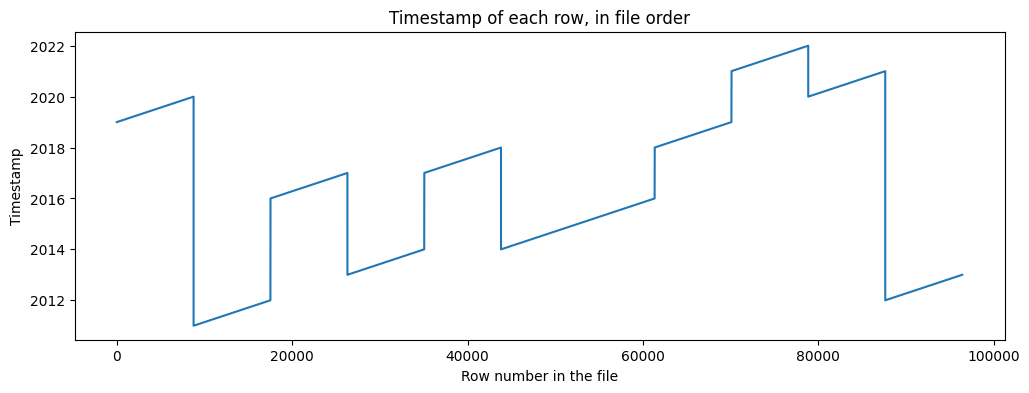

In [7]:
plt.figure(figsize=(12, 4))
plt.plot(df['Datetime'])
plt.title('Timestamp of each row, in file order')
plt.xlabel('Row number in the file')
plt.ylabel('Timestamp')
plt.show()

**Yikes.** Instead of one smooth ramp, it's a staircase that jumps up and down: the file starts in 2019, drops back to 2011, jumps to 2016... Any line plot or forecast built on this order would connect Dec 31, 2019 to Jan 1, 2011!

Let's confirm it with code instead of eyeballing it.

In [8]:
# True if every timestamp is later than the one before it
df['Datetime'].is_monotonic_increasing

False

In [9]:
# which year does each chunk of the file start with?
years_in_file_order = df['Datetime'].dt.year.drop_duplicates()
years_in_file_order.tolist()

[2019, 2011, 2016, 2013, 2017, 2014, 2015, 2018, 2021, 2020, 2012]

The file was glued together one year at a time, in a random order. This happens **all the time** in the real world (someone exports one file per year and stacks them). The fix: sort by time, then make the time the **index**.

In [10]:
# sort by time
df = df.sort_values('Datetime')

# make the datetime the index - this unlocks resample(), rolling(), and nicer plots
df = df.set_index('Datetime')

df.head()

,Demand,BDL_tmpf,BDL_dwpf,BDL_relh,BDL_drct,BDL_sknt,BDL_p01i,BDL_alti,BDL_mslp,BDL_vsby
Datetime,,,,,,,,,,
2011-01-01 00:00:00,3053.0,33.98,26.96,0.0,0.0,0.0,0.0,30.07,1018.5,6.0
2011-01-01 01:00:00,2892.0,33.98,26.96,0.0,0.0,0.0,0.0,30.07,1018.5,6.0
2011-01-01 02:00:00,2774.0,30.92,26.96,0.0,0.0,0.0,0.0,30.07,1018.6,6.0
2011-01-01 03:00:00,2710.0,30.02,26.06,0.0,0.0,0.0,0.0,30.09,1019.2,5.0
2011-01-01 04:00:00,2698.0,28.94,24.98,0.0,0.0,0.0,0.0,30.09,1019.1,5.0


In [11]:
# check again
df.index.is_monotonic_increasing

True

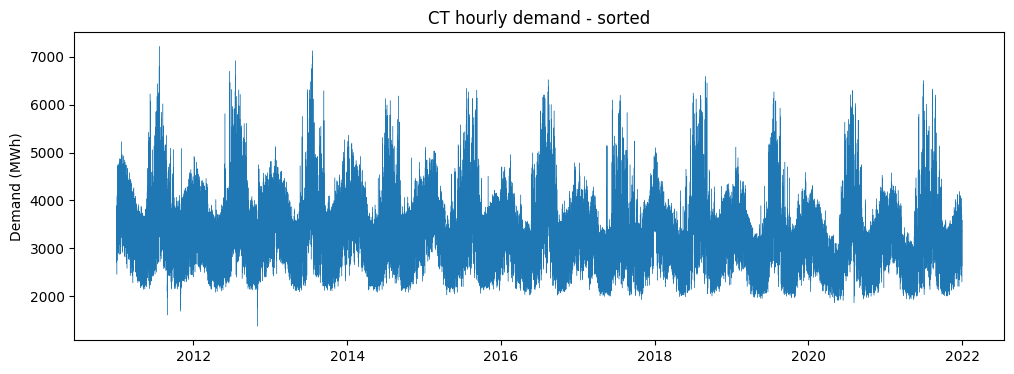

In [12]:
plt.figure(figsize=(12, 4))
plt.plot(df.index, df['Demand'], linewidth=0.3)
plt.title('CT hourly demand - sorted')
plt.ylabel('Demand (MWh)')
plt.show()

Much better! You can already see a pattern: a big spike every summer. Too many points to see much else - we'll fix that with resampling soon.

# 🔴 Problem #2: are any hours missing?
If we have every hour from the first timestamp to the last, how many rows *should* we have?

In [13]:
first_hour = df.index.min()
last_hour = df.index.max()
print('first hour:', first_hour)
print('last hour: ', last_hour)

# every hour between the first and last timestamp
all_hours = pd.date_range(start=first_hour, end=last_hour, freq='h')

print('hours we should have:', len(all_hours))
print('hours we do have:    ', len(df))

first hour: 2011-01-01 00:00:00
last hour:  2021-12-31 23:00:00
hours we should have: 96432
hours we do have:     96427


In [14]:
# which hours are missing?
missing_hours = all_hours.difference(df.index)
missing_hours

DatetimeIndex(['2011-03-13 01:00:00', '2012-03-11 01:00:00',
               '2013-03-10 01:00:00', '2014-03-09 01:00:00',
               '2015-03-08 01:00:00'],
              dtype='datetime64[us]', freq=None)

Five missing hours - and look at the dates: each one is **the middle of the night on a Sunday in March**. That's the start of **daylight saving time**, when the clocks jump forward an hour. That hour never happened! (In the first five years of this file, the data provider simply skipped it. From 2016 on, they filled it in.)

Also check for the opposite problem - the same hour showing up twice:

In [15]:
# how many duplicated timestamps?
df.index.duplicated().sum()

np.int64(0)

No duplicates. 👍

To get a clean, evenly-spaced series, `asfreq('h')` adds a row for every missing hour (filled with `NaN`). Then we fill those few gaps by **interpolating** - drawing a straight line between the hour before and the hour after.

In [16]:
# add the missing hours as empty rows
df = df.asfreq('h')

# how many missing demand values now?
df['Demand'].isna().sum()

np.int64(5)

In [17]:
# fill each gap with a straight line between its neighbors
# method='time' uses the actual timestamps to space the line
df['Demand'] = df['Demand'].interpolate(method='time')

df['Demand'].isna().sum()

np.int64(0)

# 🔴 Problem #3: missing and *impossible* weather values
Missing values (`NaN`) are easy to spot. **Impossible** values are sneakier. Look at the minimum of each column:

In [18]:
df.isna().sum()

Demand        0
BDL_tmpf    272
BDL_dwpf    272
BDL_relh    272
BDL_drct    272
BDL_sknt    272
BDL_p01i    272
BDL_alti    272
BDL_mslp    272
BDL_vsby    272
dtype: int64

In [19]:
df.describe().round(1)

,Demand,BDL_tmpf,BDL_dwpf,BDL_relh,BDL_drct,BDL_sknt,BDL_p01i,BDL_alti,BDL_mslp,BDL_vsby
count,96432.0,96160.0,96160.0,96160.0,96160.0,96160.0,96160.0,96160.0,96160.0,96160.0
mean,3388.5,52.0,39.6,65.6,221.4,7.6,0.0,30.0,1010.1,9.3
std,761.5,19.3,19.7,21.4,118.6,4.8,0.0,0.3,80.1,2.0
min,1372.0,-11.0,-27.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
25%,2843.0,36.0,25.0,49.4,170.0,4.0,0.0,29.9,1011.2,10.0
50%,3333.3,52.0,41.0,66.6,230.0,7.0,0.0,30.0,1016.3,10.0
75%,3813.0,68.0,55.9,84.4,330.0,10.0,0.0,30.2,1021.5,10.0
max,7219.0,102.0,78.1,100.0,360.0,40.0,2.0,30.8,1044.7,10.0


Stare at the `min` row:
* `BDL_mslp` (sea level pressure) has a minimum of **0 millibars**. Normal is around 1,013. Zero pressure would be outer space. 🚀
* `BDL_alti` (altimeter) also has zeros - normal is around 30 inches.
* `BDL_relh` (humidity) has zeros - air in Connecticut is never perfectly bone dry.

These zeros are the weather station's way of saying **"I don't know."** If we leave them in, every average and every model gets dragged toward zero. Recode them as missing:

In [20]:
# how many impossible zeros?
print('mslp zeros:', (df['BDL_mslp'] == 0).sum())
print('alti zeros:', (df['BDL_alti'] == 0).sum())
print('relh zeros:', (df['BDL_relh'] == 0).sum())

mslp zeros: 595
alti zeros: 3
relh zeros: 841


In [21]:
# replace the impossible zeros with NaN (missing)
df['BDL_mslp'] = df['BDL_mslp'].replace(0, np.nan)
df['BDL_alti'] = df['BDL_alti'].replace(0, np.nan)
df['BDL_relh'] = df['BDL_relh'].replace(0, np.nan)

df[['BDL_mslp', 'BDL_alti', 'BDL_relh']].describe().round(1)

,BDL_mslp,BDL_alti,BDL_relh
count,95565.0,96157.0,95319.0
mean,1016.4,30.0,66.2
std,8.1,0.2,20.6
min,971.8,28.8,9.1
25%,1011.3,29.9,49.9
50%,1016.3,30.0,67.0
75%,1021.6,30.2,84.6
max,1044.7,30.8,100.0


The minimums now make physical sense.

## The sneakiest kind: a fake value that *looks* real
Temperature's minimum is about -11°F, which is believable for a Connecticut winter, so the `min` check can't help us. But look for hours where the temperature **and** the dew point are *both exactly* 0.0:

In [22]:
# both exactly zero at the same time? suspicious!
fake_zero = (df['BDL_tmpf'] == 0) & (df['BDL_dwpf'] == 0)
print('hours where temperature AND dew point are exactly 0:', fake_zero.sum())

hours where temperature AND dew point are exactly 0: 131


In [23]:
# show the suspicious hours from July 2016
suspicious = df.loc[fake_zero, ['BDL_tmpf', 'BDL_dwpf']]
suspicious.loc['2016-07']

,BDL_tmpf,BDL_dwpf
Datetime,,
2016-07-13 10:00:00,0.0,0.0
2016-07-13 11:00:00,0.0,0.0
2016-07-13 12:00:00,0.0,0.0
2016-07-13 13:00:00,0.0,0.0


**0°F in July?** Impossible. These are more "I don't know" codes - the station sends zeros when a sensor drops out. (A few of these hours are in the bitter cold snap of January 2018, where 0°F is actually believable - but "temperature *and* dew point exactly 0.0" is a pattern we can't trust, so we treat every one as missing.)

In [24]:
# recode the fake zeros as missing
df.loc[fake_zero, 'BDL_tmpf'] = np.nan
df.loc[fake_zero, 'BDL_dwpf'] = np.nan

Temperature is the weather variable we care most about this module, so let's fill its gaps the same way we filled demand.

In [25]:
print('missing temperatures before:', df['BDL_tmpf'].isna().sum())

df['BDL_tmpf'] = df['BDL_tmpf'].interpolate(method='time')

print('missing temperatures after: ', df['BDL_tmpf'].isna().sum())

missing temperatures before: 403
missing temperatures after:  0


**Rule of thumb:** before you trust *any* column, check its `min` and `max` and ask "is that physically possible?" Zeros, `-999`, `9999` and `M` are all common codes for "missing."

# 🔴 Resample: hourly ➡️ daily
96,000 hourly points are a lot to look at. For the rest of the module we will forecast **daily** demand - the number a grid operator plans around.

`resample('D')` groups the rows into days. Then you choose how to combine each day:
* **Demand → `sum()`** - the total electricity used that day
* **Temperature → `mean()` and `max()`** - how warm the day was, and how hot it got

We'll also convert MWh to **GWh** (gigawatt-hours; 1 GWh = 1,000 MWh) so the numbers are easier to read.

In [26]:
# start an empty DataFrame and fill it one column at a time
daily = pd.DataFrame()

# total demand per day, in GWh
daily['Demand_GWh'] = df['Demand'].resample('D').sum() / 1000

# average and maximum temperature per day
daily['Temp_avg'] = df['BDL_tmpf'].resample('D').mean()
daily['Temp_max'] = df['BDL_tmpf'].resample('D').max()

daily.head()

,Demand_GWh,Temp_avg,Temp_max
Datetime,,,
2011-01-01,77.071,39.90125,50.00
2011-01-02,77.400,42.08750,48.02
2011-01-03,90.982,29.12000,33.98
2011-01-04,93.627,27.98750,39.02
2011-01-05,93.066,27.92000,37.04


In [27]:
# 11 years of days
daily.shape

(4018, 3)

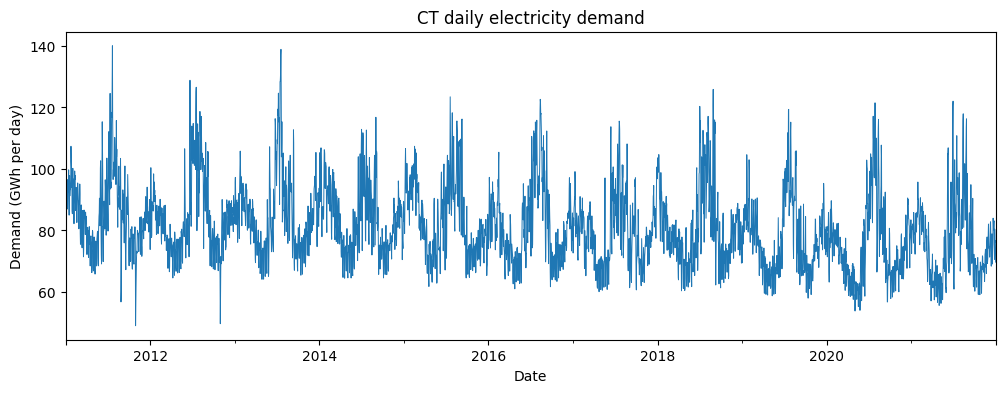

In [28]:
daily['Demand_GWh'].plot(figsize=(12, 4), linewidth=0.7)
plt.title('CT daily electricity demand')
plt.ylabel('Demand (GWh per day)')
plt.xlabel('Date')
plt.show()

## 🤔 What do you see?
Write down three things before you read on.

1. **A summer spike every year** - air conditioning.
2. **A smaller winter bump** - lights on earlier, plus some electric heat. (Most CT homes heat with oil or gas, so the winter bump is much smaller than the summer one.)
3. **A slow downhill trend** - average demand fell from about 86 GWh/day in 2011 to about 76 GWh/day in 2021. Think LED light bulbs, more efficient appliances, and rooftop solar panels (the power a home makes for itself never shows up as demand on the grid).

# 🔴 Rolling averages: see the trend through the noise
A **rolling average** (also called a moving average) replaces each day with the average of the last *N* days. The bigger the window, the smoother the line.

In [29]:
daily['Rolling_7'] = daily['Demand_GWh'].rolling(window=7).mean()
daily['Rolling_365'] = daily['Demand_GWh'].rolling(window=365).mean()

daily[['Demand_GWh', 'Rolling_7', 'Rolling_365']].tail(10)

,Demand_GWh,Rolling_7,Rolling_365
Datetime,,,
2021-12-22,80.21395,76.640543,76.326986
2021-12-23,82.40763,78.188179,76.329556
2021-12-24,83.13257,80.195123,76.351471
2021-12-25,75.71744,80.497743,76.373042
2021-12-26,70.61287,79.801780,76.356366
2021-12-27,80.40759,79.290359,76.362672
2021-12-28,76.12504,78.373870,76.352281
2021-12-29,76.75664,77.879969,76.342400
2021-12-30,74.29761,76.721394,76.317340


Notice the first 6 rows of `Rolling_7` (and the first 364 of `Rolling_365`) are `NaN` - you can't average 7 days until you *have* 7 days.

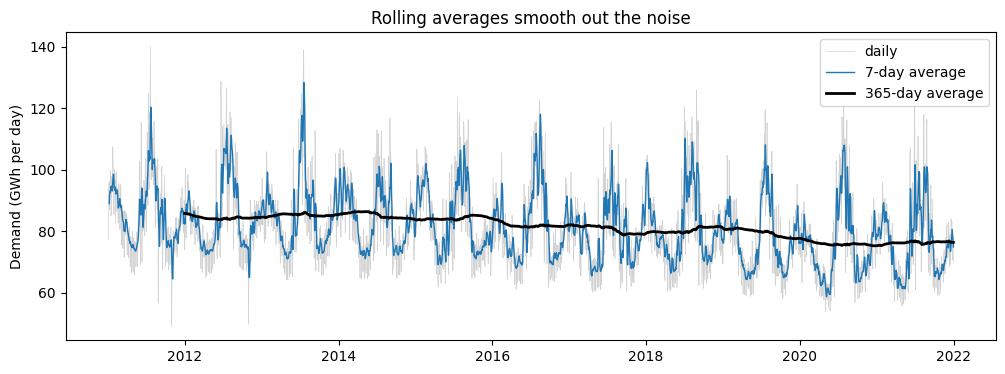

In [30]:
plt.figure(figsize=(12, 4))
plt.plot(daily.index, daily['Demand_GWh'], linewidth=0.5, color='lightgray', label='daily')
plt.plot(daily.index, daily['Rolling_7'], linewidth=1, label='7-day average')
plt.plot(daily.index, daily['Rolling_365'], linewidth=2, color='black', label='365-day average')
plt.title('Rolling averages smooth out the noise')
plt.ylabel('Demand (GWh per day)')
plt.legend()
plt.show()

The 365-day average makes the downward trend impossible to miss.

⚠️ **Hold that thought:** a rolling average *describes* the past. Next week we turn it into a **forecast** - and there's a sneaky way to cheat by accident when you do. Stay tuned.

# 🔴 The three clocks of electricity demand
Demand follows three repeating cycles. Forecasters call repeating cycles **seasonality**.

## Clock #1: hour of the day

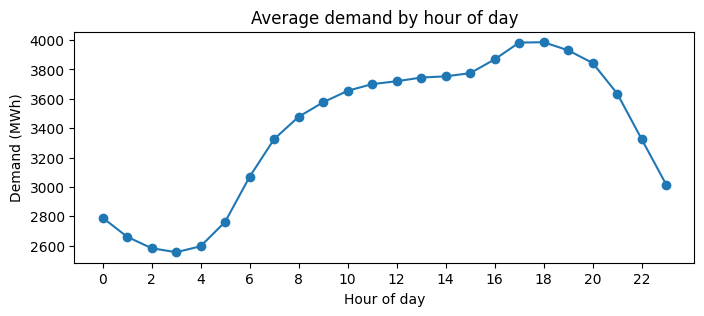

In [31]:
# average demand for each hour of the day (0 = midnight, 18 = 6 PM)
hourly_profile = df.groupby(df.index.hour)['Demand'].mean()

hourly_profile.plot(marker='o', figsize=(8, 3))
plt.title('Average demand by hour of day')
plt.xlabel('Hour of day')
plt.ylabel('Demand (MWh)')
plt.xticks(range(0, 24, 2))
plt.show()

Lowest around **3 AM** (everyone is asleep), highest around **6 PM** (people get home, cook dinner, turn on lights and TVs).

## Clock #2: day of the week

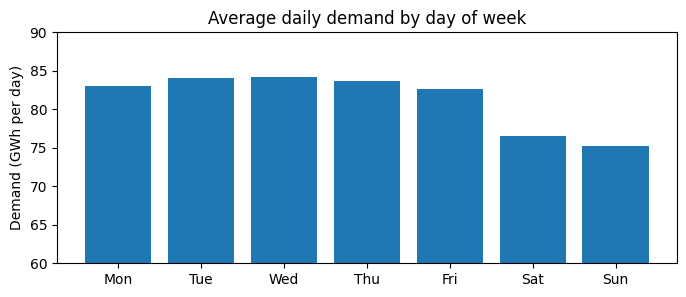

In [32]:
# dayofweek: 0 = Monday ... 6 = Sunday
weekday_profile = daily.groupby(daily.index.dayofweek)['Demand_GWh'].mean()

weekday_names = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']

plt.figure(figsize=(8, 3))
plt.bar(weekday_names, weekday_profile)
plt.title('Average daily demand by day of week')
plt.ylabel('Demand (GWh per day)')
plt.ylim(60, 90)
plt.show()

Weekends are about **9% lower** - offices and factories are closed. (Notice the y-axis starts at 60, not 0. That makes differences easier to see, but always check the axis before you get too excited!)

## Clock #3: month of the year

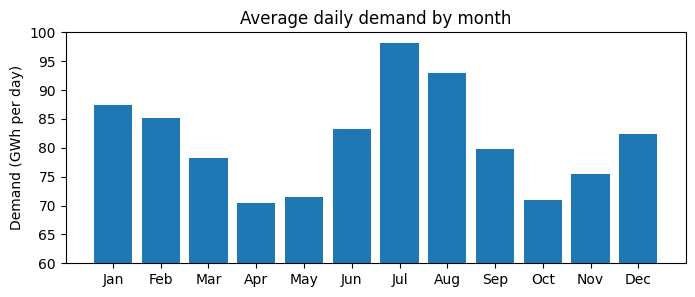

In [33]:
monthly_profile = daily.groupby(daily.index.month)['Demand_GWh'].mean()

month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

plt.figure(figsize=(8, 3))
plt.bar(month_names, monthly_profile)
plt.title('Average daily demand by month')
plt.ylabel('Demand (GWh per day)')
plt.ylim(60, 100)
plt.show()

**July** is the peak, **April and October** are the lows (no heat, no AC - the "shoulder" months).

## Two clocks at once: a heatmap
What does a typical day look like in each month? A heatmap shows hour of day (rows) against month (columns).

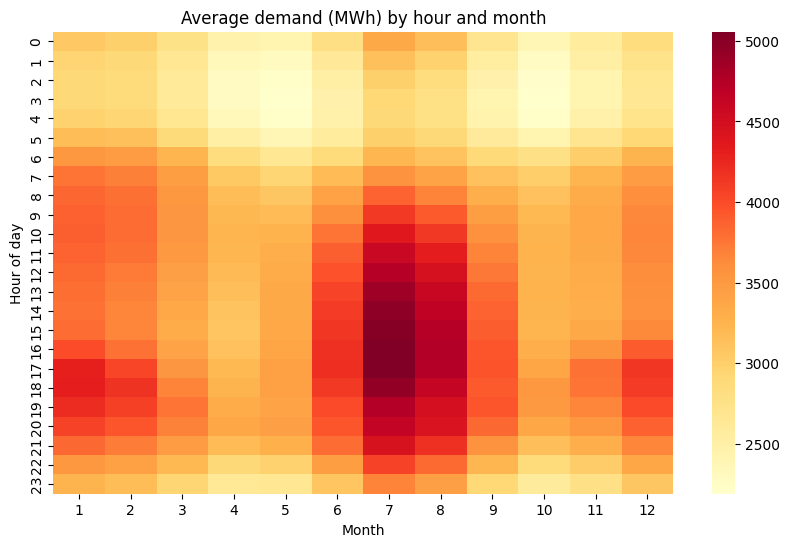

In [34]:
# add helper columns for the hour and the month
df['hour'] = df.index.hour
df['month'] = df.index.month

# average demand for every hour-month combination
hour_by_month = df.pivot_table(index='hour', columns='month', values='Demand', aggfunc='mean')

plt.figure(figsize=(10, 6))
sns.heatmap(hour_by_month, cmap='YlOrRd')
plt.title('Average demand (MWh) by hour and month')
plt.xlabel('Month')
plt.ylabel('Hour of day')
plt.show()

The hottest cells are **summer afternoons and early evenings** (AC running full blast). Winter has a smaller peak in the **early evening**, when it gets dark early.

# 🔴 Temperature drives demand
If the clocks explain the *pattern*, weather explains the *surprises*. Plot each day's demand against its average temperature:

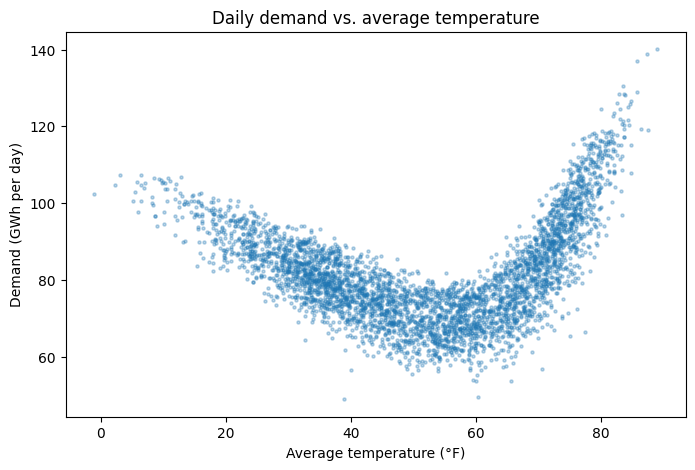

In [35]:
plt.figure(figsize=(8, 5))
plt.scatter(daily['Temp_avg'], daily['Demand_GWh'], s=5, alpha=0.3)
plt.title('Daily demand vs. average temperature')
plt.xlabel('Average temperature (°F)')
plt.ylabel('Demand (GWh per day)')
plt.show()

It's a **hockey stick** (some people call it a smile):
* Demand is **lowest around 50-65°F** - comfortable weather, no heating or cooling needed.
* As it gets **hotter**, demand climbs fast - air conditioning.
* As it gets **colder**, demand climbs slowly - lights, electric heat, and furnace fans.

This is why weather forecasts are the most important input to an electricity forecast.

# 🔴 Every outlier has a story
Which days used the **least** electricity?

In [36]:
daily.nsmallest(6, 'Demand_GWh')[['Demand_GWh', 'Temp_avg']].round(1)

,Demand_GWh,Temp_avg
Datetime,,
2011-10-30,49.0,39.0
2012-10-30,49.7,60.3
2020-05-03,53.8,65.7
2020-05-02,53.9,60.0
2020-05-24,54.0,59.5
2020-05-17,55.2,60.2


These aren't days when people decided to save energy:
* **Oct 30, 2011** - the day after the **"Snowtober" nor'easter**: heavy wet snow on trees that still had their leaves knocked out power to hundreds of thousands of CT homes for days. (Remember the fake zero temperatures? Twenty of them are from this storm - the weather station lost power too!)
* **Oct 30, 2012** - the day after **Hurricane Sandy** made landfall, with widespread outages across the state.
* **May 2020** - mild weather, weekends, and a state largely shut down for COVID-19.

**Low demand on a storm day means customers *couldn't* use power** - the demand was still there, but the wires were down.

And the days that used the **most** electricity?

In [37]:
daily.nlargest(6, 'Demand_GWh')[['Demand_GWh', 'Temp_avg', 'Temp_max']].round(1)

,Demand_GWh,Temp_avg,Temp_max
Datetime,,,
2011-07-22,140.1,89.1,102.0
2013-07-19,138.9,87.3,96.1
2013-07-18,137.1,85.9,95.0
2013-07-17,130.4,83.5,93.9
2012-06-21,128.8,85.8,96.1
2013-07-16,128.5,83.0,93.0


**Heat waves.** July 22, 2011 hit about 102°F at Bradley, and mid-July 2013 had a week-long heat wave.

**Forecasting lesson:** a model learns from *all* of its history - including the storms and heat waves. A good forecaster knows where the strange days are and why they happened.

# 🔴 Save your clean daily data
We'll start from this exact file next week.

In [38]:
# keep just the columns we built
clean_daily = daily[['Demand_GWh', 'Temp_avg', 'Temp_max']]

# saves to the Files panel on the left in Colab
clean_daily.to_csv('ct_daily_demand_2011_2021.csv')

clean_daily.tail()

,Demand_GWh,Temp_avg,Temp_max
Datetime,,,
2021-12-27,80.40759,32.262500,37.0
2021-12-28,76.12504,37.416667,46.9
2021-12-29,76.75664,37.354167,39.9
2021-12-30,74.29761,40.966667,45.0
2021-12-31,69.70594,45.450000,48.2


(A copy of this same file is also saved in the course repo, in case you need it: [data/ct_daily_demand_2011_2021.csv](https://raw.githubusercontent.com/drdave-teaching/OPIM3510-notebooks/master/data/ct_daily_demand_2011_2021.csv).)

# 🔴 Sneak peek: the simplest forecasts, and a scorecard
Next week we start forecasting. Every model we build has to beat the two simplest forecasts in the world:

* **Naive:** tomorrow will be the same as today. → `shift(1)`
* **Seasonal naive:** tomorrow will be the same as the same day *last week*. → `shift(7)`

`shift(1)` slides the whole column down one row, so each day sits next to *yesterday's* value. That's a forecast made using only information we would have had at the time.

In [39]:
daily['Naive'] = daily['Demand_GWh'].shift(1)
daily['Seasonal_naive'] = daily['Demand_GWh'].shift(7)

daily[['Demand_GWh', 'Naive', 'Seasonal_naive']].head(10)

,Demand_GWh,Naive,Seasonal_naive
Datetime,,,
2011-01-01,77.071,NaN,NaN
2011-01-02,77.400,77.071,NaN
2011-01-03,90.982,77.400,NaN
2011-01-04,93.627,90.982,NaN
2011-01-05,93.066,93.627,NaN
2011-01-06,95.673,93.066,NaN
2011-01-07,94.772,95.673,NaN
2011-01-08,87.394,94.772,77.071
2011-01-09,86.971,87.394,77.400


## Meet `evaluate()` - our scorecard for the whole module
Instead of rewriting error metrics in every notebook, we'll use one function. It returns:

| Metric | Question it answers |
|---|---|
| `n` | how many time steps were scored |
| `bias` | on average, do we over-forecast (+) or under-forecast (−)? |
| `MAE` | on average, how far off are we, in the original units (GWh)? |
| `RMSE` | like MAE, but big misses count extra |
| `MAPE (%)` | on average, how far off are we, in percent? |
| `skill vs naive (%)` | how much smaller our MAE is than the naive forecast's MAE (only if you pass `naive=`) |

**Sign convention, all module long:** `error = predicted − actual`. A positive error means we **over**-forecast.

Read every line of the function below - you should be able to explain each one. (It is also saved in the course repo as `Module2_TimeSeriesForecasting/forecast_helpers.py`.)

In [40]:
def evaluate(actual, predicted, naive=None):
    """Score a forecast. Returns a pandas Series you can stack into a leaderboard.

    actual    : the true values (Series, list, or numpy array)
    predicted : your forecast for the same time steps
    naive     : (optional) a baseline forecast for the same time steps.
                If you give one, you also get "skill vs naive (%)":
                how much smaller your MAE is than the baseline's MAE.
                Positive = you beat the baseline. Negative = the baseline wins.

    Rows where any of the forecasts is missing (NaN) are dropped first,
    so every model is scored on exactly the same time steps.
    """
    # put everything side by side so the rows line up
    scores = pd.DataFrame({"actual": actual, "predicted": predicted})
    if naive is not None:
        scores["naive"] = naive

    # only score time steps where we have every number
    scores = scores.dropna()

    # error = predicted - actual
    error = scores["predicted"] - scores["actual"]

    # the four forecast KPIs
    bias = error.mean()
    mae = error.abs().mean()
    rmse = np.sqrt((error ** 2).mean())
    mape = (error.abs() / scores["actual"].abs()).mean() * 100

    results = {
        "n": len(scores),
        "bias": bias,
        "MAE": mae,
        "RMSE": rmse,
        "MAPE (%)": mape,
    }

    # how much better than the baseline?
    if naive is not None:
        naive_error = scores["naive"] - scores["actual"]
        naive_mae = naive_error.abs().mean()
        results["skill vs naive (%)"] = (1 - mae / naive_mae) * 100

    return pd.Series(results).round(2)

Let's score both simple forecasts on **2021** (the last year of data). Which one do you think will win? Make a guess before you run the next cell!

In [41]:
# score only 2021
test = daily.loc['2021']

naive_scores = evaluate(test['Demand_GWh'], test['Naive'], naive=test['Naive'])
seasonal_scores = evaluate(test['Demand_GWh'], test['Seasonal_naive'], naive=test['Naive'])

# stack the scorecards into a leaderboard (one row per model)
leaderboard = pd.DataFrame({'Naive (yesterday)': naive_scores,
                            'Seasonal naive (same day last week)': seasonal_scores})
leaderboard = leaderboard.T
leaderboard

,n,bias,MAE,RMSE,MAPE (%),skill vs naive (%)
Naive (yesterday),365.0,0.02,4.79,6.68,6.15,0.00
Seasonal naive (same day last week),365.0,0.06,8.11,11.97,10.22,-69.55


**Surprise!** "Same as yesterday" beats "same as last week" by a mile - its MAPE is about 6% vs. about 10%. Its skill vs. naive is 0% by definition (it *is* the naive forecast), and the seasonal naive is *negative*: it loses to the baseline.

Why? **Weather is sticky.** A hot Tuesday is usually followed by a hot Wednesday, so yesterday's demand is a great guess for today's. Last week's demand might have been on a completely different weather pattern. The day-of-week clock is real, but the weather clock matters more.

So the **naive forecast is the bar to beat**. Off by about 6% on an average day with zero effort - a fancy model has to do better than that to earn its keep. That's next week.

# 🦾 On your own
1. **Resample by week.** Make a weekly version of `daily` with `resample('W')`. Which week of the year uses the most electricity?
2. **Pick a year.** Plot just 2015 (`daily.loc['2015']`) with its 7-day rolling average. Can you spot July 4th? Thanksgiving?
3. **Another clock.** Make the hourly profile (Clock #1) for **weekdays only** and **weekends only** on one plot. How does the shape change?
4. **Hot days only.** Filter to days with `Temp_max` above 90°F. What's their average demand vs. all other days?
5. **Ask Claude to explain** the difference between `asfreq()` and `resample()`. Then **check its answer yourself**: run both on `df.head(48)` and compare how many rows you get back.
6. **Beat naive?** Try a "two-day average" forecast: the average of yesterday and the day before (`rolling(2).mean()` - be careful about *which* days go into the average!). Score it with `evaluate()` on 2021. Does it beat naive?

# 🔴 Conclusion
You took a messy file with **out-of-order rows, missing hours and impossible zeros** and turned it into a clean daily time series. You found the three clocks of demand, the temperature hockey stick, and the stories behind the outliers. And you learned the most important rule in forecasting: **always compare against the naive forecast.**

Next week: moving average models, honest train/test splits, and the sneaky way to cheat by accident.